## Word Count Program - Performance testing

This notebook will provide an insight into the differences in runtimes for my Word Count program and how the performances and duration changes as more resources are used during the spark job.

All the spark jobs performed within these tests will be conducted over the 100gb Wikipedia XML Dataset. Using the `time spark-submit` command, I was able to gather the runtime of each of the jobs and insert the data I gathered into an excel sheet to present my findings. 

In [2]:
import pandas as pd

performanceData_cores = pd.read_excel("FYP_performance_testing.xlsx", "WordCount performance - Cores")

performanceData_cores


,num_executors,executor_cores,executor_memory,total_cores,runtime_seconds
0,2,2,4G,4,9136
1,4,2,4G,8,6155
2,4,3,4G,12,3625
3,4,4,4G,16,3119
4,5,4,4G,20,2403
5,8,3,4G,24,2228
6,7,4,4G,28,1718
7,8,4,4G,32,1383
8,9,4,4G,36,1276


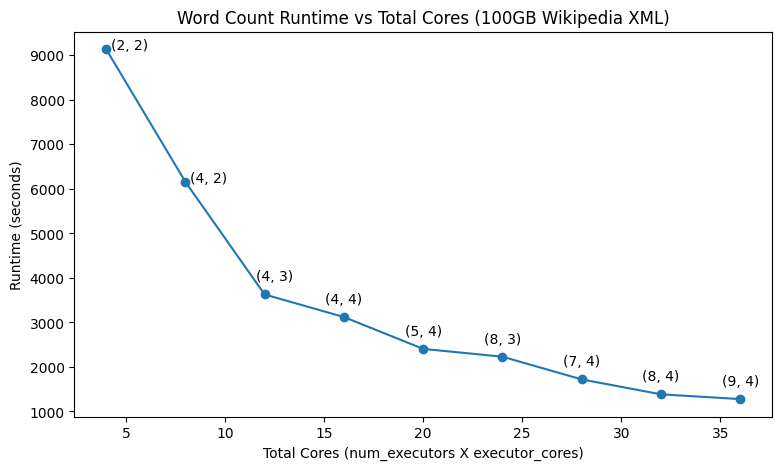

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

plt.plot(performanceData_cores["total_cores"],
         performanceData_cores["runtime_seconds"],
         marker="o")

for i, row in performanceData_cores.iterrows():
    label = f"({row['num_executors']}, {row['executor_cores']})"
    if row['total_cores'] > 15:
        plt.annotate(
            label,
            (row['total_cores'], row['runtime_seconds']),
            textcoords="offset points",
            xytext=(0,10),
            ha='center'
        )
    elif row['total_cores'] == 12:
        plt.annotate(
            label,
            (row['total_cores'], row['runtime_seconds']),
            textcoords="offset points",
            xytext=(7,10),
            ha='center'
        )
    else:
        plt.annotate(
            label,
            (row['total_cores'], row['runtime_seconds']),
            textcoords="offset points",
            xytext=(17,0),
            ha='center'
        )

plt.title("Word Count Runtime vs Total Cores (100GB Wikipedia XML)")
plt.xlabel("Total Cores (num_executors X executor_cores)")
plt.ylabel("Runtime (seconds)")

plt.show()

## Break Down of Results - total cores:

### Rapid Improvement - 4 -> 12 total cores:

- Runtime drops significantly
- Suggests that the workload is highly parallisable
- Adding cores distributes work evenly

### Slower Improvement - 12 -> 24 total cores:

- Since the server is one machine, split into different vms, not several different machines
- Could cause the non-linear pattern from continuing due to bottlenecks like the disk, network or shuffle subsystem.

### Diminishing Returns - 28 -> 36 total cores:

- This could be due to the server being one machine -> memory bandwidth is shared between the 'datanodes' as its split into various different VM's
- All the traffic is going through the same underlying network

In [8]:
performanceData_executors = pd.read_excel("FYP_performance_testing.xlsx", "WordCount perf - Executors")

performanceData_executors

,num_executors,executor_cores,executor_memory,runtime_seconds
0,1,1,4G,29515
1,2,1,4G,16529
2,3,1,4G,11684
3,4,1,4G,9005
4,5,1,4G,6539
5,6,1,4G,5902
6,7,1,4G,5107
7,8,1,4G,4308
8,9,1,4G,4003
9,10,1,4G,3158


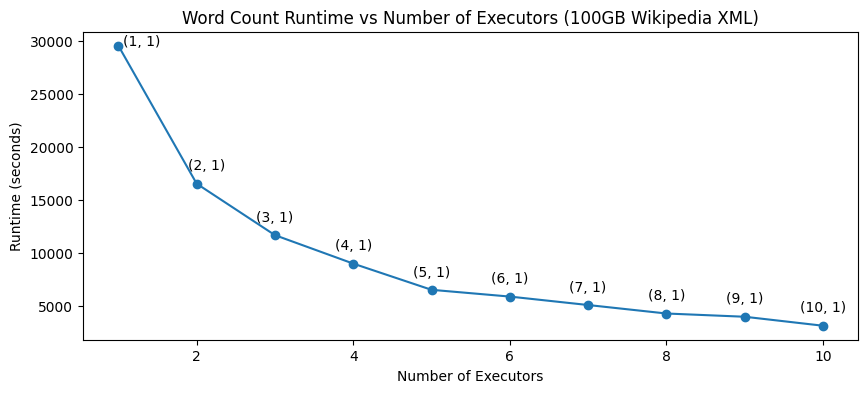

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.plot(performanceData_executors["num_executors"],
         performanceData_executors["runtime_seconds"],
         marker="o")

for i, row in performanceData_executors.iterrows():
    label = f"({row['num_executors']}, {row['executor_cores']})"
    if row['num_executors'] == 1:
        plt.annotate(
            label,
            (row['num_executors'], row['runtime_seconds']),
            textcoords="offset points",
            xytext=(17,0),
            ha='center'
        )
    elif row['num_executors'] == 2:
        plt.annotate(
            label,
            (row['num_executors'], row['runtime_seconds']),
            textcoords="offset points",
            xytext=(7,10),
            ha='center'
        )
    else:
        plt.annotate(
            label,
            (row['num_executors'], row['runtime_seconds']),
            textcoords="offset points",
            xytext=(0,10),
            ha='center'
        )

plt.title("Word Count Runtime vs Number of Executors (100GB Wikipedia XML)")
plt.xlabel("Number of Executors")
plt.ylabel("Runtime (seconds)")

plt.show()

## Break Down of Results - executors:

### Massive improvement - approx 30,000 sec -> 3,000 sec:

- There is a 10x improvement from 1 executor to 10 executors
- This also mirrors the pattern shown from the rate of improvement in the total cores experiment

### Improvement comes from the parallelism, not memory:

- Adding the executors with one core improves consistency
- The server has 10 executors so its the maximum limit

In [20]:
performanceData_dataset = pd.read_excel("FYP_performance_testing.xlsx", "WordCount perf - Datasets")

performanceData_dataset

,Dataset_GB,num_executor,executor_cores,executor_mem,driver_mem,runtime_seconds
0,10,2,4,4G,4G,584
1,10,4,4,4G,4G,396
2,10,6,4,4G,4G,206
3,10,8,4,4G,4G,201
4,10,10,4,4G,4G,158
5,20,2,4,4G,4G,988
6,20,4,4,4G,4G,608
7,20,6,4,4G,4G,344
8,20,8,4,4G,4G,271
9,20,10,4,4G,4G,274


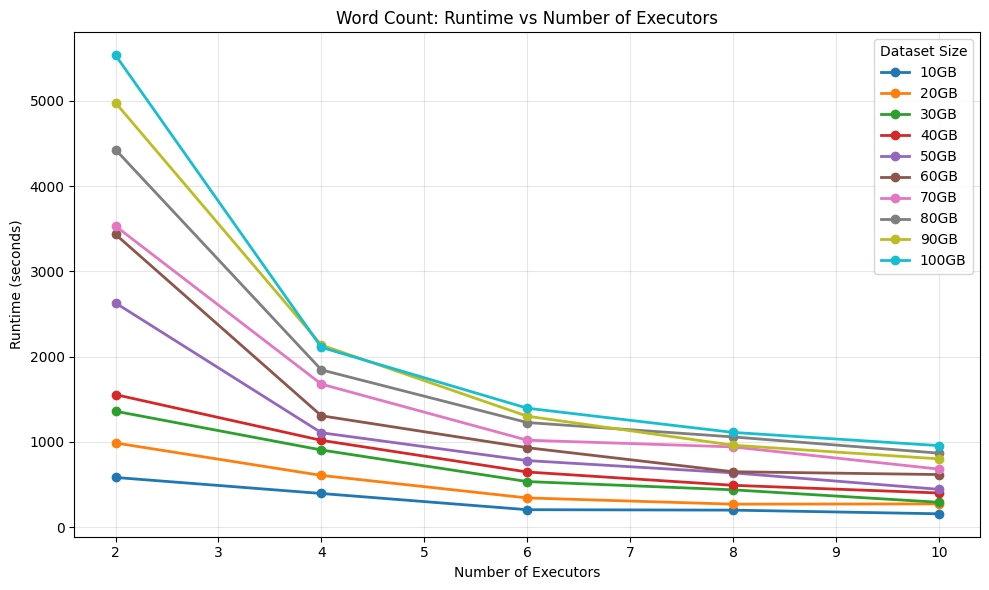

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

df = performanceData_dataset.copy()

df["Dataset_GB"] = pd.to_numeric(df["Dataset_GB"])
df["num_executor"] = pd.to_numeric(df["num_executor"])
df["runtime_seconds"] = pd.to_numeric(df["runtime_seconds"])

colour_map = {
    10:  "tab:blue",
    20:  "tab:orange",
    30:  "tab:green",
    40:  "tab:red",
    50:  "tab:purple",
    60:  "tab:brown",
    70:  "tab:pink",
    80:  "tab:gray",
    90:  "tab:olive",
    100: "tab:cyan",
}

plt.figure(figsize=(10, 6))

for dataset_gb in sorted(df["Dataset_GB"].unique()):
    g = performanceData_dataset[performanceData_dataset["Dataset_GB"] == dataset_gb].sort_values("num_executor")

    x = g["num_executor"].to_numpy()
    y = g["runtime_seconds"].to_numpy()

    c = colour_map.get(int(dataset_gb), None)

    # Plot the curve
    plt.plot(
        x, y,
        marker="o",
        linewidth=2,
        color=c,
        label=f"{int(dataset_gb)}GB"
    )

plt.title("Word Count: Runtime vs Number of Executors")
plt.xlabel("Number of Executors")
plt.ylabel("Runtime (seconds)")
plt.grid(True, alpha=0.3)
plt.legend(title="Dataset Size")
plt.tight_layout()
plt.show()

## Break Down of Results - Datasets:

### Diminishing returns

- This graph has a strong alignment with amdahl's law 
- suggested by:
    - large performance growth from 2 - 4 
    - flattened curve from 6 - 10
- Speed up is limited by sequential components of the workload

- Also shows aspect of Gustafson's law
    - workloads for higher dataset sizes are consistently above lower dataset sizes
    - eg. 100gb data points are above 20gb data points
    - the shape of performance still matches throughout the dataset sizes (approximately)
     

### Slight inconsistency

- This could be due to performing these spark jobs at different times
- Number of factors such as more users on the server, more programs and jobs being run on the server at different times, hardware changes due to earlier issues